# Tool-Guard reproduction analysis

Load data and perform sanity checks

In [16]:
from pathlib import Path
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

EXPECTED_TASKS = {"banking": 16, "workspace": 40, "slack": 21, "travel": 20}
CONDS = ["benign", "benign_defense", "attack", "attack_defense"]
DEFENSE_FIELDS = ["total_validations", "passed_validations", "failed_alignment",
              "failed_suspicion", "replans_triggered", "aborts"]

RESULTS_DIR = Path("../results/reproduction")

def parse_path(path, root):
    parts = path.relative_to(root).parts
    model_dir = parts[0]

    if model_dir == "gemma4_26b":
        configuration = "default"
        run = None
    elif model_dir == "qwen35_9b":
        configuration = parts[1]
        run = None
        if len(parts) >= 4 and parts[2].startswith("run"):
            run = parts[2]
    else:
        return None

    return {
        "configuration": configuration,
        "run": run,
    }


def load_experiments(root):
    run_records = []
    task_records = []

    for path in sorted(root.rglob("*.json")):
        metadata = parse_path(path, root)

        if metadata is None:
            continue

        with open(path, "r") as f:
            data = json.load(f)

        # Unique identifier for this JSON file
        run_id = str(path.relative_to(root).with_suffix(""))

        common = {
            **metadata,
            "run_id": run_id,
            "file": str(path),
        }

        # Suite-level data
        run_record = {
            **data,
            **common,
        }

        # Keep individual task results out of the run-level DataFrame
        run_record.pop("results", None)
        run_records.append(run_record)

        # Task-level data
        for result in data.get("results", []):
            task_records.append({
                **common,
                "model": data.get("model"),
                "provider": data.get("provider"),
                "suite": data.get("suite"),
                "defense": data.get("defense"),
                "attack_strategy": data.get("attack_strategy"),
                "adaptive_type": data.get("adaptive_type"),
                **result,
            })

    runs_df = pd.json_normalize(run_records, sep="_")
    tasks_df = pd.json_normalize(task_records, sep="_")

    return runs_df, tasks_df


runs_df, tasks_df = load_experiments(RESULTS_DIR)

print(f"Loaded {len(runs_df)} suite runs")
print(f"Loaded {len(tasks_df)} task executions")

Loaded 36 suite runs
Loaded 873 task executions


In [3]:
print("=== RUNS ===")
display(
    runs_df.groupby(
        ["model", "configuration", "run"],
        dropna=False
    ).size().rename("n_files").reset_index()
)

print("=== SUITES ===")
display(
    runs_df.groupby(
        ["model", "configuration", "suite"],
        dropna=False
    ).size().rename("n_runs").reset_index()
)

print("=== TASK COUNTS ===")
display(
    tasks_df.groupby(
        ["run_id", "suite"]
    ).size().rename("actual_tasks").reset_index()
)

=== RUNS ===


,model,configuration,run,n_files
0,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,NaN,4
1,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,NaN,4
2,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run0,4
3,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run1,4
4,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run2,4
5,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run3,4
6,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run4,4
7,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,run5,4
8,google/gemma-4-26b-a4b-it:free,default,NaN,4


=== SUITES ===


,model,configuration,suite,n_runs
0,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,banking,1
1,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,slack,1
2,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,travel,1
3,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,workspace,1
4,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,banking,1
5,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,slack,1
6,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,travel,1
7,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,workspace,1
8,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,banking,6
9,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,slack,6


=== TASK COUNTS ===


,run_id,suite,actual_tasks
0,gemma4_26b/banking,banking,16
1,gemma4_26b/slack,slack,21
2,gemma4_26b/travel,travel,20
3,gemma4_26b/workspace,workspace,40
4,qwen35_9b/nothink/banking_nothink,banking,16
5,qwen35_9b/nothink/slack_nothink,slack,21
6,qwen35_9b/nothink/travel_nothink,travel,20
7,qwen35_9b/nothink/workspace_nothink,workspace,40
8,qwen35_9b/think_nothink_val/banking_think_noth...,banking,16
9,qwen35_9b/think_nothink_val/slack_think_nothin...,slack,21


In [ ]:
task_check = (
    tasks_df.groupby(["run_id", "suite"])
    .size()
    .rename("actual_tasks")
    .reset_index()
)

task_check["expected_tasks"] = task_check["suite"].map(EXPECTED_TASKS)
task_check["valid"] = (
    task_check["actual_tasks"] == task_check["expected_tasks"]
)

# Sanity check for unexpected tasks: table should be empty
display(task_check[~task_check["valid"]])

,run_id,suite,actual_tasks,expected_tasks,valid


In [5]:
METRIC_LABELS = {
    "benign_utility": "ben_util",
    "benign_defense_utility": "ben_def_util",
    "attack_utility": "att_util",
    "attack_defense_utility": "att_def_util",
    "asr_no_defense": "asr_no_def",
    "asr_with_defense": "asr_with_def",
    "false_positive_rate": "false_pos_rate",
}

available_metrics = [m for m in METRIC_LABELS if m in runs_df.columns]

# 1. Per-suite results
summary = (
    runs_df.groupby(
        ["model", "configuration", "suite"],
        dropna=False
    )[available_metrics]
    .mean()
    .round(3)
    .rename(columns=METRIC_LABELS)
)

print("=== RESULTS PER SUITE ===")
display(summary)

# 2. Overall results (average across suites)
all_summary = (
    runs_df.groupby(
        ["model", "configuration"],
        dropna=False
    )[available_metrics]
    .mean()
    .round(3)
    .rename(columns=METRIC_LABELS)
)

print("=== OVERALL RESULTS (ALL SUITES) ===")
display(all_summary.reset_index())

=== RESULTS PER SUITE ===


ben_util  \
model                           configuration            suite                 
RedHatAI/Qwen3.5-9B-FP8-dynamic nothink                  banking       0.750   
                                                         slack         0.810   
                                                         travel        0.750   
                                                         workspace     0.950   
                                think_nothink_val        banking       0.875   
                                                         slack         0.810   
                                                         travel        0.800   
                                                         workspace     0.925   
                                think_nothink_val_tokens banking       0.719   
                                                         slack         0.881   
                                                         travel        0.625   
                                                         workspace     0.892   
google/gemma-4-26b-a4b-it:free  default                  banking       0.812   
                                                         slack         0.952   
                                                         travel        0.750   
                                                         workspace     0.950   

                                                                    ben_def_util  \
model                           configuration            suite                     
RedHatAI/Qwen3.5-9B-FP8-dynamic nothink                  banking           0.688   
                                                         slack             0.714   
                                                         travel            0.800   
                                                         workspace         0.925   
                                think_nothink_val        banking           0.688   
                                                         slack             0.714   
                                                         travel            0.750   
                                                         workspace         0.875   
                                think_nothink_val_tokens banking           0.688   
                                                         slack             0.675   
                                                         travel            0.608   
                                                         workspace         0.833   
google/gemma-4-26b-a4b-it:free  default                  banking           0.812   
                                                         slack             0.857   
                                                         travel            0.700   
                                                         workspace         0.950   

                                                                    att_util  \
model                           configuration            suite                 
RedHatAI/Qwen3.5-9B-FP8-dynamic nothink                  banking       0.875   
                                                         slack         0.762   
                                                         travel        0.450   
                                                         workspace     0.775   
                                think_nothink_val        banking       0.688   
                                                         slack         0.667   
                                                         travel        0.100   
                                                         workspace     0.750   
                                think_nothink_val_tokens banking       0.688   
                                                         slack         0.651   
                                                         travel        0.100   
                                                         workspace     0.5

=== OVERALL RESULTS (ALL SUITES) ===


,model,configuration,ben_util,ben_def_util,att_util,att_def_util,asr_no_def,asr_with_def,false_pos_rate
0,RedHatAI/Qwen3.5-9B-FP8-dynamic,nothink,0.815,0.782,0.715,0.517,0.415,0.025,0.143
1,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val,0.852,0.757,0.551,0.400,0.757,0.103,0.209
2,RedHatAI/Qwen3.5-9B-FP8-dynamic,think_nothink_val_tokens,0.779,0.701,0.509,0.413,0.729,0.052,0.219
3,google/gemma-4-26b-a4b-it:free,default,0.866,0.830,0.605,0.312,0.713,0.006,0.042


Now prepare to plot metrics: labels, plot settings, helper functions etc.

In [33]:
# Model labels
MODEL_LABELS = {
    "google/gemma-4-26b-a4b-it:free": "Gemma 4",
    "RedHatAI/Qwen3.5-9B-FP8-dynamic": "Qwen3.5",
}

CONFIG_LABELS = {
    ("default", "Gemma 4"): "Gemma 4",
    ("nothink", "Qwen3.5"): "Qwen3.5-NT",
    ("think_nothink_val", "Qwen3.5"): "Qwen3.5-T",
    ("think_nothink_val_tokens", "Qwen3.5"): "Qwen3.5-T",
}

# Short labels for plots
CONDITION_LABELS = {
    "benign": "Benign",
    "benign_defense": "Benign + defense",
    "attack": "Attack",
    "attack_defense": "Attack + defense",
}

DEFENSE_LABEL = ["No Def.", "w/ Def."]

GROUPS = ["Gemma 4", "Qwen3.5-NT", "Qwen3.5-T"]

# Matplotlib defaults
plt.rcParams.update({
    "figure.figsize": (2, 1.8),
    "font.size": 7,
    "axes.titlesize": 8,
    "axes.labelsize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,
    "figure.dpi": 150,
})

# Helper for plots labels
def add_model_config_labels(df):
    df = df.copy()
    df["model_label"] = df["model"].map(MODEL_LABELS)
    df["model_config"] = df.apply(
        lambda row: CONFIG_LABELS.get(
            (row["configuration"], row["model_label"]),
            f"{row['model_label']} ({row['configuration']})"
        ),
        axis=1
    )
    return df

# Add readable model/configuration labels
plot_df = runs_df.copy()

plot_df["model_label"] = plot_df["model"].map(MODEL_LABELS)

plot_df["model_config"] = plot_df.apply(
    lambda row: CONFIG_LABELS.get(
        (row["configuration"], row["model_label"]),
        f"{row['model_label']} ({row['configuration']})"
    ),
    axis=1
)

plot_df["weight"] = plot_df["suite"].str.lower().map(EXPECTED_TASKS)

# Calculate number of independent runs
run_counts = (
    plot_df.groupby("model_config")["run"]
    .apply(lambda x: x.nunique() + int(x.isna().any()))
)

# Display labels, including run counts
GROUP_LABELS = [
    f"{group}\n(n={run_counts[group]})"
    for group in GROUPS
]

# Helper function for the plotting grouped metrics
def plot_grouped_metrics(
    df,
    metrics,
    labels,
    title,
    ylabel,
    ylim=None,
    figsize=(2, 1.8),
    percentage=False,
    show_values=False,
    fig_label=None,
):
    n_metrics = len(metrics)

    x = np.arange(len(GROUPS))
    width = 0.8 / n_metrics

    fig, ax = plt.subplots(figsize=figsize)

    for i, (metric, label) in enumerate(
        zip(metrics, labels)
    ):
        tmp = df.assign(_wx=df[metric] * df["weight"])
        grouped = tmp.groupby("model_config")
        values = (grouped["_wx"].sum() / grouped["weight"].sum()).reindex(GROUPS)

        if percentage:
            values = values * 100

        bars = ax.bar(
            x + (i - (n_metrics - 1) / 2) * width,
            values,
            width,
            label=label,
            edgecolor="black",
            linewidth=0.4,
        )

        if show_values:
            for bar in bars:
                height = bar.get_height()

                if pd.notna(height):
                    ax.annotate(
                        f"{height:.1f}" if percentage else f"{height:.2f}",
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 4),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        fontsize=5,
                    )

    ax.set_ylabel(ylabel, labelpad=0)
    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(GROUP_LABELS, rotation=0, ha="center")
    ax.tick_params(axis='x', width=0.4, length=1, pad=2)
    ax.tick_params(axis='y', width=0.4, length=1, pad=1)
    ax.margins(x=0.0)
    
    ax.spines["left"].set_linewidth(0.4)
    ax.spines["bottom"].set_linewidth(0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if ylim is not None:
        ax.set_ylim(*ylim)


    ax.legend(frameon=False, loc="upper right", borderpad=0,
            handlelength=1, handletextpad=0.4, borderaxespad=0)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()

    if fig_label:
        fig.savefig(f"./figures/{fig_label}.pdf", bbox_inches='tight', pad_inches=0.01)

    plt.show()

## Attack success rate

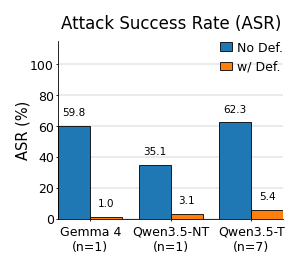

In [34]:
asr_metrics = ["asr_no_defense", "asr_with_defense"]

plot_grouped_metrics(
    df=plot_df,
    metrics=asr_metrics,
    labels=DEFENSE_LABEL,
    title="Attack Success Rate (ASR)",
    ylabel="ASR (%)",
    ylim=(0, 115),
    percentage=True,
    show_values=True,
    fig_label="repro_asr"
)

## Utility comparison

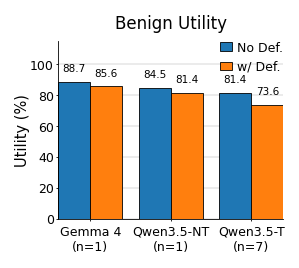

In [10]:
benign_metrics = [
    "benign_utility",
    "benign_defense_utility",
]

plot_grouped_metrics(
    df=plot_df,
    metrics=benign_metrics,
    labels=DEFENSE_LABEL,
    title="Benign Utility",
    ylabel="Utility (%)",
    ylim=(0, 115),
    percentage=True,
    show_values=True,
    fig_label="repro_benign_utility"
)

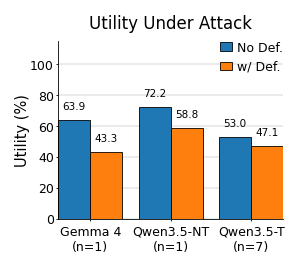

In [11]:
attack_metrics = [
    "attack_utility",
    "attack_defense_utility",
]

plot_grouped_metrics(
    df=plot_df,
    metrics=attack_metrics,
    labels=DEFENSE_LABEL,
    title="Utility Under Attack",
    ylabel="Utility (%)",
    ylim=(0, 115),
    percentage=True,
    show_values=True,
    fig_label="repro_attack_utility"
)

## Latency

In [32]:
latency_df = runs_df[
    runs_df["configuration"].isin([
        "default",  # gemma4_26b
        "nothink",
        "think_nothink_val",
        "think_nothink_val_tokens",
    ])
].copy()

# Standardize configuration names
latency_df["configuration"] = latency_df["configuration"].replace({
    "default": "gemma4_26b",
    "nothink": "qwen-NT",
    "think_nothink_val": "qwen-T",
    "think_nothink_val_tokens": "qwen-T",
})

# Extract average latency per suite (seconds)
latency_rows = []

for _, row in latency_df.iterrows():
    for cond in ["benign", "attack"]:
        for defense in [False, True]:
            suffix = f"{cond}_defense" if defense else cond

            latency_rows.append({
                "config": row["configuration"],
                "defense": "def" if defense else "no_def",
                "cond": cond,
                "suite": row["suite"],
                "latency_s": row[f"latency_stats_{suffix}_avg_s"],
            })

latency_long = pd.DataFrame(latency_rows)

# Pivot into table
latency_table = latency_long.pivot_table(
    index=["config", "defense", "cond"],
    columns="suite",
    values="latency_s",
    aggfunc="mean",
)

latency_table = latency_table[
    ["banking", "slack", "travel", "workspace"]
].round(2)

print("\nAVERAGE LATENCY PER SUITE (seconds)")
print("=" * 85)
print(latency_table.to_string())
print("=" * 85)



AVERAGE LATENCY PER SUITE (seconds)
suite                      banking  slack  travel  workspace
config     defense cond                                     
gemma4_26b def     attack    19.45  22.64   30.92      43.64
                   benign    25.27  41.74   60.51      36.46
           no_def  attack    16.39  19.50   38.92      19.58
                   benign     6.81  10.86   20.56      13.60
qwen-NT    def     attack    10.92  25.63   25.96      20.76
                   benign    13.99  20.32   33.29      19.04
           no_def  attack     5.95   6.76   16.07       8.26
                   benign     3.86   5.80   13.13       7.78
qwen-T     def     attack    45.92  36.02   90.19      38.66
                   benign    36.13  28.26   55.20      32.35
           no_def  attack    14.71  17.90   31.13      12.82
                   benign    10.82   8.42   22.45      11.93


## Stability analysis for Qwen3.5-T

In [23]:

metrics = [
    "benign_utility",
    "attack_utility",
    "asr_with_defense",
]

# Select both folder structures belonging to this experiment
stability_df = runs_df[
    runs_df["configuration"].isin([
        "think_nothink_val",
        "think_nothink_val_tokens",
    ])
].copy()

# Identify individual experimental runs
stability_df["experiment_run"] = stability_df.apply(
    lambda r: (
        r["configuration"]
        if pd.isna(r["run"])
        else f"{r['configuration']}/{r['run']}"
    ),
    axis=1,
)

# Check that each run contains all four suites
for run, group in stability_df.groupby("experiment_run"):
    actual = set(group["suite"])

    if actual != EXPECTED_TASKS.keys() or len(group) != 4:
        raise ValueError(
            f"{run}: expected 4 suites, found {actual}"
        )

# Aggregate suite metrics into one weighted result per run
run_results = []

for run, group in stability_df.groupby("experiment_run"):
    weights = group["total_tasks"]

    row = {
        "run": run,
        "total_tasks": weights.sum(),
    }

    for metric in metrics:
        row[metric] = np.average(
            group[metric],
            weights=weights
        )

    run_results.append(row)

stability_runs = pd.DataFrame(run_results)

# Calculate mean and standard deviation across runs
summary = stability_runs[metrics].agg(["mean", "std"]).T

# Convert to percentages
summary[["mean", "std"]] *= 100

summary = summary.rename(index={
    "benign_utility": "Benign Utility",
    "attack_utility": "Attack Utility",
    "asr_with_defense": "ASR w/ Defense",
})

summary["Mean ± Std"] = summary.apply(
    lambda r: f"{r['mean']:.2f}% ± {r['std']:.2f}%",
    axis=1,
)

# Print results
print(f"\nQwen3.5-T stability analysis ({len(stability_runs)} runs)")
print("=" * 45)
print(summary[["Mean ± Std"]].to_string())
print("=" * 45)



Qwen3.5-T stability analysis (7 runs)
                    Mean ± Std
Benign Utility  81.44% ± 3.47%
Attack Utility  53.02% ± 3.25%
ASR w/ Defense   5.45% ± 2.64%


## Utility failure analysis

Check how many tasks that failed utility also made zero tool calls, that is to say both planners chose no tool and the run ended with no action taken.

In [8]:
from pathlib import Path

results_directory = Path("../results/reproduction/qwen35_9b/")

# Benign+def runs, no tools called, utility=false
ben_search_string = (
    "Both plans returned no tool, generating final response\n"
    "[SplitReplan] Generated proper final response from LLM\n"
    "      DEBUG BENIGN+DEF: Utility=False, Tools=[]"
)

ben_failed_util_string = "BENIGN+DEF: Utility=False"

# Attack+def runs, no tools called, utility=false
att_search_string = (
    "Both plans returned no tool, generating final response\n"
    "[SplitReplan] Generated proper final response from LLM\n"
    "      DEBUG ATTACK+DEF: Utility=False, Tools=[]"
)

att_failed_util_string = "ATTACK+DEF: Utility=False"

# Initialize counters
totals = {
    "no_think": {
        "att_no_tool_called": 0,
        "att_total_utility_fails": 0,
        "att_total_runs": 0,
        "ben_no_tool_called": 0,
        "ben_total_utility_fails": 0,
        "ben_total_runs": 0
    },
    "think_nothink_val": {
        "att_no_tool_called": 0,
        "att_total_utility_fails": 0,
        "att_total_runs": 0,
        "ben_no_tool_called": 0,
        "ben_total_utility_fails": 0,
        "ben_total_runs": 0
    }
}

files_count = {
    "no_think": 0,
    "think_nothink_val": 0
}

# Search recursively
for log_file in results_directory.rglob("*.log"):

    # Identify category based on parent directory
    if "nothink" in log_file.parts:
        category = "no_think"

    elif ("think_nothink_val" in log_file.parts or
          "think_nothink_val_tokens" in log_file.parts):
        category = "think_nothink_val"

    else:
        continue

    with open(log_file, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()

    counts = {
        "att_no_tool_called": content.count(att_search_string),
        "att_total_utility_fails": content.count(att_failed_util_string),
        "ben_no_tool_called": content.count(ben_search_string),
        "ben_total_utility_fails": content.count(ben_failed_util_string)
    }

    # count total runs
    counts["att_total_runs"] = content.count("ATTACK+DEF:")
    counts["ben_total_runs"] = content.count("BENIGN+DEF:")

    # Update totals
    for key, count in counts.items():
        totals[category][key] += count

    files_count[category] += 1

# Print summary
print("=" * 95)
print("SUMMARY")
print("=" * 95)

print(f"{'Category':<22} {'Type':<10} {'Runs':>8} "
      f"{'Failures':>10} {'Fail %':>9} "
      f"{'No Tool':>10} {'No Tool / Fail %':>18}")

print("-" * 95)

for category, t in totals.items():
    for prefix, label in [("att", "Attack"), ("ben", "Benign")]:
        runs = t[f"{prefix}_total_runs"]
        fails = t[f"{prefix}_total_utility_fails"]
        no_tool = t[f"{prefix}_no_tool_called"]

        fail_pct = fails / runs * 100 if runs else 0
        no_tool_fail_pct = no_tool / fails * 100 if fails else 0

        print(f"{category:<22} {label:<10} {runs:>8} "
              f"{fails:>10} {fail_pct:>8.2f}% "
              f"{no_tool:>10} {no_tool_fail_pct:>16.2f}%")

print("-" * 95)
print("GRAND TOTALS")

for prefix, label in [("att", "Attack"), ("ben", "Benign")]:
    runs = sum(t[f"{prefix}_total_runs"] for t in totals.values())
    fails = sum(t[f"{prefix}_total_utility_fails"] for t in totals.values())
    no_tool = sum(t[f"{prefix}_no_tool_called"] for t in totals.values())

    fail_pct = fails / runs * 100 if runs else 0
    no_tool_fail_pct = no_tool / fails * 100 if fails else 0

    print(f"{label:<10} {runs:>8} runs | "
          f"Failures: {fails:>5} ({fail_pct:>6.2f}%) | "
          f"No-tool share: {no_tool_fail_pct:>6.2f}%")

print("=" * 95)

SUMMARY
Category               Type           Runs   Failures    Fail %    No Tool   No Tool / Fail %
-----------------------------------------------------------------------------------------------
no_think               Attack           97         40    41.24%         21            52.50%
no_think               Benign           97         18    18.56%          0             0.00%
think_nothink_val      Attack          679        359    52.87%        112            31.20%
think_nothink_val      Benign          679        179    26.36%          6             3.35%
-----------------------------------------------------------------------------------------------
GRAND TOTALS
Attack          776 runs | Failures:   399 ( 51.42%) | No-tool share:  33.33%
Benign          776 runs | Failures:   197 ( 25.39%) | No-tool share:   3.05%


### Validator rejections & utility

Check how many validations ended in rejections. Also, investigate whether validation rejections are associated with utility failures in benign tasks by comparing success rates between tasks with and without rejections. Sometimes the validator may be right to reject a tool call even in the benign setting: the planner might pick the wrong tool.

* `tasks_with_rejection`: proportion of tasks where the validator rejected at least one tool call
* `rejected`: number of tool calls that failed validation
* `validated`: number of proposed tool calls that underwent validation (all tool calls suggested by planner)
* `rejection_rate_per_call`: proportion of rejected vs total validated

In [11]:
import re
from pathlib import Path
import pandas as pd

results_directory = Path("../results/reproduction/qwen35_9b/")

# One marker per finished task; everything BEFORE it belongs to that task
marker = re.compile(r"(BENIGN\+DEF|ATTACK\+DEF): Utility=(True|False)")

rejected_pat = re.compile(r"Validation FAILED", re.I) # Appears once per failed validation
validated_pat = re.compile(r"Chosen:", re.I) # Triggers a validation - use this to count how many validations happened

rows = []
for log_file in results_directory.rglob("*.log"):
    if "nothink" in log_file.parts:
        category = "no_think"
    elif "think_nothink_val" in log_file.parts or "think_nothink_val_tokens" in log_file.parts:
        category = "think"
    else:
        continue
    
    text = log_file.read_text(encoding="utf-8", errors="ignore")
    start = 0
    for m in marker.finditer(text):
        chunk = text[start:m.start()]      # the task's log
        start = m.end()
        rows.append(dict(
            file=log_file.name, path=str(log_file), category=category,
            setting=m.group(1), utility=(m.group(2) == "True"),
            n_rejected=len(rejected_pat.findall(chunk)),
            n_validated=len(validated_pat.findall(chunk)),
        ))

df = pd.DataFrame(rows)
df["has_rejection"] = df.n_rejected > 0

summary = df.groupby(["category", "setting"]).agg(
    tasks=("utility", "size"),
    tasks_with_rejection=("has_rejection", "mean"),
    rejected=("n_rejected", "sum"),
    validated=("n_validated", "sum"),
)
summary["rejection_rate_per_call"] = summary.rejected / summary.validated
print(summary.to_string())
print()

# Does a rejection/failed validation in a benign run go with failure?
print(df[df.setting == "BENIGN+DEF"].groupby(["category", "has_rejection"]).utility.mean())

                     tasks  tasks_with_rejection  rejected  validated  rejection_rate_per_call
category setting                                                                              
no_think ATTACK+DEF     97              0.525773       106        325                 0.326154
         BENIGN+DEF     97              0.247423        83        414                 0.200483
think    ATTACK+DEF    679              0.671576       777       1988                 0.390845
         BENIGN+DEF    679              0.244477       443       2684                 0.165052

category  has_rejection
no_think  False            0.849315
          True             0.708333
think     False            0.801170
          True             0.536145
Name: utility, dtype: float64
